# Tellwarden: Web Security Scanner and Offline Rule-Based IDS Simulator

**Student:** Vansh  |  **Programme:** IBM SkillsBuild Cyber Security 2026 (BharatCares)

Tellwarden is an educational cybersecurity project with two modules.

* **Module A, Web Security Scanner.** Checks HTTPS, security headers and CORS behaviour of a web response and explains each result with a fix.
* **Module B, Offline IDS Simulator.** Applies seven transparent, rule-based detections to log events (brute force, password spraying, port scans, request bursts and more).

**Design rules for this project**

* No machine learning and no AI model. Every detection is a readable rule with a threshold.
* The IDS is offline. It reads sample or uploaded log events and never watches live traffic.
* The scanner analyses response snapshots. Live fetching is off by default and needs an explicit authorisation flag.
* All sample data is synthetic and uses documentation IP ranges (192.0.2.0/24, 198.51.100.0/24, 203.0.113.0/24).

Run the notebook from top to bottom. Every part ends with self-checks (`assert`) so a wrong result stops the run.

In [1]:
import csv, io, ipaddress, json, random, re, socket
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone, timedelta
from pathlib import Path
from urllib.parse import urlsplit, urljoin

import matplotlib.pyplot as plt
import pandas as pd

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70)
print("Setup complete. Output folder:", OUT.resolve())

Setup complete. Output folder: /home/claude/submission/outputs


## Part A. Offline IDS Simulator

### A1. Event model and rule catalogue

Each log line becomes an `Event`. Time is stored as epoch seconds (UTC) so window maths is simple.

The seven rules, with the safe range allowed for each threshold. The defaults are teaching values, not tuned for a real network.

| Rule | Detects | MITRE ATT&CK |
|---|---|---|
| AUTH-001 | Brute force: many failed logins from one address | T1110.001 |
| AUTH-002 | Password spraying: many usernames, few tries each | T1110.003 |
| AUTH-003 | Success after failures from the same address and user | T1110, T1078 |
| AUTH-004 | Login outside allowed hours | T1078 |
| NET-001 | Vertical scan: many ports on one host | T1046 |
| NET-002 | Horizontal scan: one port across many hosts | T1046 |
| WEB-001 | Request burst from one address | T1499 (indicative) |

In [2]:
@dataclass(frozen=True)
class Event:
    id: str
    t: float                      # epoch seconds, UTC
    event_type: str               # auth_success | auth_failure | conn | http_request
    src_ip: str
    dst_ip: str | None = None
    dst_port: int | None = None
    username: str | None = None
    service: str | None = None
    status: str | None = None

EVENT_TYPES = ("auth_success", "auth_failure", "conn", "http_request")

def iso(t: float) -> str:
    return datetime.fromtimestamp(t, tz=timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

RULES = {
    "AUTH-001": dict(name="Brute force", severity="high", attack="T1110.001",
        why="Repeated failed logins from one address often mean a script is guessing passwords.",
        response="Rate limit or block the source, require stronger authentication, check whether any attempt later succeeded.",
        params={"threshold": (2, 50, 5), "window": (30, 3600, 300)}),
    "AUTH-002": dict(name="Password spraying", severity="high", attack="T1110.003",
        why="One address trying a few passwords against many accounts avoids per-account lockouts.",
        response="Block the source, alert the affected accounts, enforce multi-factor authentication.",
        params={"distinct": (3, 100, 10), "window": (60, 3600, 600), "per_user": (1, 5, 2)}),
    "AUTH-003": dict(name="Success after failures", severity="critical", attack="T1110, T1078",
        why="A successful login right after many failures can mean the attacker guessed the password.",
        response="Treat the account as compromised: reset credentials, end sessions, review activity after the login.",
        params={"failures": (2, 50, 5), "window": (60, 3600, 600)}),
    "AUTH-004": dict(name="Unusual hour login", severity="low", attack="T1078",
        why="Logins outside normal working hours can indicate stolen credentials. Also a common false positive.",
        response="Confirm with the user. Compare with their usual pattern before escalating.",
        params={"start_hour": (0, 23, 7), "end_hour": (0, 23, 20)}),
    "NET-001": dict(name="Vertical port scan", severity="medium", attack="T1046",
        why="Many distinct ports on one host in a short time is how scanners map open services.",
        response="Block or rate limit the source and check which ports are exposed.",
        params={"ports": (5, 200, 15), "window": (10, 600, 60)}),
    "NET-002": dict(name="Horizontal scan", severity="medium", attack="T1046",
        why="One port probed across many hosts is how scanners look for a single vulnerable service.",
        response="Block the source and confirm the targeted service is patched and not exposed.",
        params={"hosts": (3, 200, 10), "window": (10, 600, 60)}),
    "WEB-001": dict(name="Request burst", severity="medium", attack="T1499 (indicative)",
        why="A very high request rate from one address can be a bot, a scraper or a denial of service attempt.",
        response="Apply rate limiting. Check whether the traffic is a legitimate client or a monitoring tool.",
        params={"threshold": (20, 5000, 100), "window": (10, 600, 60)}),
}
SEVERITY_ORDER = {"critical": 4, "high": 3, "medium": 2, "low": 1}

def default_config():
    return {rid: {k: v[2] for k, v in r["params"].items()} for rid, r in RULES.items()}

def validate_config(cfg):
    """Return a list of problems. An empty list means every value is a whole number inside its safe range."""
    problems = []
    for rid, r in RULES.items():
        for k, (lo, hi, _) in r["params"].items():
            v = cfg.get(rid, {}).get(k)
            if not isinstance(v, int) or isinstance(v, bool) or not lo <= v <= hi:
                problems.append(f"{rid}.{k} must be a whole number from {lo} to {hi}, got {v!r}")
    return problems

@dataclass
class Finding:
    rule_id: str
    rule_name: str
    severity: str
    attack: str
    entity: str
    first_seen: str
    last_seen: str
    observed: str
    threshold: str
    window: str
    metric: int
    evidence_ids: list = field(default_factory=list)
    explanation: str = ""
    response: str = ""
    id: str = ""

assert validate_config(default_config()) == []
print(len(RULES), "rules loaded. Default configuration is valid.")

7 rules loaded. Default configuration is valid.


### A2. Detection engine

The engine is a **pure function**: the same events and settings always return the same findings.

Count and distinct rules use a **sliding time window** with incremental state, so a long log does not need a full re-scan for every event. Overlapping windows are merged, so one incident produces one finding instead of dozens.

In [3]:
def slide(evs, window_s, tracker, ok):
    """Slide a window over time-sorted events of one group. Merge overlapping hits into spans."""
    spans, left = [], 0
    for i, e in enumerate(evs):
        tracker.add(e)
        while e.t - evs[left].t > window_s:
            tracker.remove(evs[left]); left += 1
        m = tracker.value()
        if not ok(m):
            continue
        if spans and left <= spans[-1]["end"]:
            s = spans[-1]; s["end"] = i; s["start"] = min(s["start"], left); s["peak"] = max(s["peak"], m)
        else:
            spans.append({"start": left, "end": i, "peak": m})
    return spans

class CountTracker:
    def __init__(self): self.n = 0
    def add(self, e): self.n += 1
    def remove(self, e): self.n -= 1
    def value(self): return self.n

class DistinctTracker:
    """Counts distinct keys. If per_key_max is set, a key seen more often than that voids the window (spraying)."""
    def __init__(self, key, per_key_max=None):
        self.key, self.cap, self.c = key, per_key_max, Counter()
    def add(self, e): self.c[self.key(e)] += 1
    def remove(self, e):
        k = self.key(e); self.c[k] -= 1
        if self.c[k] <= 0: del self.c[k]
    def value(self):
        if self.cap is not None and any(v > self.cap for v in self.c.values()): return 0
        return len(self.c)

def group_by(items, key):
    g = defaultdict(list)
    for x in items: g[key(x)].append(x)
    return g

def _finding(rid, entity, evs, observed, threshold, window, metric):
    r = RULES[rid]
    return Finding(rid, r["name"], r["severity"], r["attack"], entity, iso(evs[0].t), iso(evs[-1].t),
                   observed, threshold, window, metric, [e.id for e in evs], r["why"], r["response"])

def analyse(events, config=None):
    """Apply all seven rules. Returns findings sorted by severity, then time, with ids F-001, F-002, ..."""
    cfg = config or default_config()
    problems = validate_config(cfg)
    if problems: raise ValueError("; ".join(problems))
    ev = sorted(events, key=lambda e: e.t)
    out = []

    c = cfg["AUTH-001"]
    for ip, evs in group_by([e for e in ev if e.event_type == "auth_failure"], lambda e: e.src_ip).items():
        for s in slide(evs, c["window"], CountTracker(), lambda m: m >= c["threshold"]):
            out.append(_finding("AUTH-001", f"src_ip {ip}", evs[s["start"]:s["end"]+1],
                f"{s['peak']} failed logins within {c['window']} s", f"{c['threshold']} failures", f"{c['window']} s", s["peak"]))

    c = cfg["AUTH-002"]
    for ip, evs in group_by([e for e in ev if e.event_type == "auth_failure" and e.username], lambda e: e.src_ip).items():
        for s in slide(evs, c["window"], DistinctTracker(lambda e: e.username, c["per_user"]), lambda m: m >= c["distinct"]):
            out.append(_finding("AUTH-002", f"src_ip {ip}", evs[s["start"]:s["end"]+1],
                f"{s['peak']} distinct usernames, at most {c['per_user']} tries each", f"{c['distinct']} usernames", f"{c['window']} s", s["peak"]))

    c = cfg["AUTH-003"]
    auth = [e for e in ev if e.event_type in ("auth_failure", "auth_success") and e.username]
    for (user, ip), evs in group_by(auth, lambda e: (e.username, e.src_ip)).items():
        hits, peak = [], 0
        for i, e in enumerate(evs):
            if e.event_type != "auth_success": continue
            prior = [x for x in evs[:i] if x.event_type == "auth_failure" and e.t - x.t <= c["window"]]
            if len(prior) >= c["failures"]:
                peak = max(peak, len(prior))
                hits += [p for p in prior if p not in hits] + [e]
        if hits:
            hits.sort(key=lambda e: e.t)
            out.append(_finding("AUTH-003", f"{user} from {ip}", hits,
                f"Successful login after {peak} failed attempts", f"{c['failures']} failures", f"{c['window']} s", peak))

    c = cfg["AUTH-004"]
    hour = lambda e: datetime.fromtimestamp(e.t, tz=timezone.utc).hour
    odd = [e for e in ev if e.event_type == "auth_success" and e.username and (hour(e) < c["start_hour"] or hour(e) >= c["end_hour"])]
    for user, evs in group_by(odd, lambda e: e.username).items():
        out.append(_finding("AUTH-004", f"user {user}", evs,
            f"{len(evs)} login(s) outside {c['start_hour']:02d}:00 to {c['end_hour']:02d}:00 UTC",
            f"outside {c['start_hour']}:00 to {c['end_hour']}:00", "per event", len(evs)))

    conns = [e for e in ev if e.event_type == "conn" and e.dst_ip and e.dst_port is not None]
    c = cfg["NET-001"]
    for (ip, dst), evs in group_by(conns, lambda e: (e.src_ip, e.dst_ip)).items():
        for s in slide(evs, c["window"], DistinctTracker(lambda e: e.dst_port), lambda m: m >= c["ports"]):
            out.append(_finding("NET-001", f"src_ip {ip} to {dst}", evs[s["start"]:s["end"]+1],
                f"{s['peak']} distinct ports within {c['window']} s", f"{c['ports']} ports", f"{c['window']} s", s["peak"]))
    c = cfg["NET-002"]
    for (ip, port), evs in group_by(conns, lambda e: (e.src_ip, e.dst_port)).items():
        for s in slide(evs, c["window"], DistinctTracker(lambda e: e.dst_ip), lambda m: m >= c["hosts"]):
            out.append(_finding("NET-002", f"src_ip {ip}, port {port}", evs[s["start"]:s["end"]+1],
                f"{s['peak']} distinct hosts within {c['window']} s", f"{c['hosts']} hosts", f"{c['window']} s", s["peak"]))

    c = cfg["WEB-001"]
    for ip, evs in group_by([e for e in ev if e.event_type == "http_request"], lambda e: e.src_ip).items():
        for s in slide(evs, c["window"], CountTracker(), lambda m: m > c["threshold"]):
            out.append(_finding("WEB-001", f"src_ip {ip}", evs[s["start"]:s["end"]+1],
                f"{s['peak']} requests within {c['window']} s", f"more than {c['threshold']}", f"{c['window']} s", s["peak"]))

    out.sort(key=lambda f: (-SEVERITY_ORDER[f.severity], f.first_seen))
    for i, f in enumerate(out, 1): f.id = f"F-{i:03d}"
    return out

def findings_df(findings):
    return pd.DataFrame([{"id": f.id, "rule": f.rule_id, "name": f.rule_name, "severity": f.severity,
                          "entity": f.entity, "first_seen": f.first_seen, "observed": f.observed,
                          "evidence": len(f.evidence_ids)} for f in findings])
print("Engine ready.")

Engine ready.


### A3. Synthetic sample data

Six scenarios are generated locally with a fixed random seed, so every run gives identical data. Normal background traffic comes from internal addresses. Each attack is injected with known timing, so we know which rule **should** fire.

| Scenario | Injected behaviour | Expected rules |
|---|---|---|
| brute_force | 14 failures on `admin`, then 6 on `demo.user`, then a success | AUTH-001, AUTH-003 |
| password_spraying | 13 usernames from one address | AUTH-002 (AUTH-001 also possible) |
| port_scan | 41 ports on one host, and port 445 on 14 hosts | NET-001, NET-002 |
| request_burst | 164 requests in about one minute | WEB-001 |
| mixed | all of the above inside normal traffic, plus one 02:14 login | all seven |
| normal | everyday traffic only, plus one 02:14 login | AUTH-004 (a false-positive demo) |

In [4]:
DAY = datetime(2026, 10, 24, tzinfo=timezone.utc).timestamp()
at = lambda h, m, s=0: DAY + h * 3600 + m * 60 + s
INTERNAL = [f"192.0.2.{20 + i}" for i in range(12)]
USERS = ["alice.example", "bob.example", "carol.example", "dev.example", "ops.example", "demo.user"]

class Builder:
    def __init__(self, prefix): self.prefix, self.items = prefix, []
    def add(self, t, **kw): self.items.append((t, kw))
    def build(self):
        self.items.sort(key=lambda x: x[0])
        return [Event(id=f"{self.prefix}-{i:04d}", t=t, **kw) for i, (t, kw) in enumerate(self.items, 1)]

def baseline(b, seed, count, odd_login=False):
    r = random.Random(seed)
    for _ in range(count):
        t = at(8, 0) + r.randrange(10 * 3600)
        k = r.random()
        if k < 0.18:   b.add(t, event_type="auth_success", src_ip=r.choice(INTERNAL), username=r.choice(USERS[:5]), service="web", status="200")
        elif k < 0.21: b.add(t, event_type="auth_failure", src_ip=r.choice(INTERNAL), username=r.choice(USERS[:5]), service="web", status="401")
        elif k < 0.30: b.add(t, event_type="conn", src_ip=r.choice(INTERNAL), dst_ip="192.0.2.10", dst_port=r.choice([22, 80, 443, 443, 443]))
        else:          b.add(t, event_type="http_request", src_ip=r.choice(INTERNAL), service="web", status=r.choice(["200", "200", "200", "304", "404"]))
    if odd_login:
        b.add(at(2, 14, 9), event_type="auth_success", src_ip="192.0.2.31", username="carol.example", service="ssh", status="ok")

def brute_force(b):
    ip = "203.0.113.45"
    for i in range(14): b.add(at(10, 41, i * 20), event_type="auth_failure", src_ip=ip, dst_ip="192.0.2.10", dst_port=22, username="admin", service="ssh", status="invalid password")
    for i in range(6):  b.add(at(10, 47, i * 15), event_type="auth_failure", src_ip=ip, dst_ip="192.0.2.10", dst_port=22, username="demo.user", service="ssh", status="invalid password")
    b.add(at(10, 48, 55), event_type="auth_success", src_ip=ip, dst_ip="192.0.2.10", dst_port=22, username="demo.user", service="ssh", status="ok")

def spraying(b):
    ip = "198.51.100.62"
    names = ["admin", "alice.example", "bob.example", "carol.example", "dev.example", "ops.example", "guest", "test", "backup", "support", "finance", "hr", "info"]
    for i, u in enumerate(names):
        b.add(at(13, 5, i * 50), event_type="auth_failure", src_ip=ip, username=u, service="web", status="401")
        if i % 4 == 0: b.add(at(13, 5, i * 50 + 25), event_type="auth_failure", src_ip=ip, username=u, service="web", status="401")

def scans(b):
    for i in range(41): b.add(at(15, 20, int(i * 1.1)), event_type="conn", src_ip="198.51.100.17", dst_ip="192.0.2.10", dst_port=20 + (i * 37) % 9000)
    for i in range(14): b.add(at(16, 2, i * 3), event_type="conn", src_ip="198.51.100.99", dst_ip=f"192.0.2.{i + 1}", dst_port=445)

def burst(b):
    for i in range(164): b.add(at(11, 30, int(i * 0.36)), event_type="http_request", src_ip="192.0.2.88", service="web", status="404" if i % 9 == 0 else "200")

def make_scenario(name, seed, normal, parts, odd=False):
    b = Builder(name[:3].upper()); baseline(b, seed, normal, odd)
    for p in parts: p(b)
    return b.build()

SCENARIOS = {
    "brute_force":       dict(events=make_scenario("brute_force", 11, 160, [brute_force]),        expected={"AUTH-001", "AUTH-003"}),
    "password_spraying": dict(events=make_scenario("password_spraying", 22, 160, [spraying]),       expected={"AUTH-002"}),
    "port_scan":         dict(events=make_scenario("port_scan", 33, 160, [scans]),                  expected={"NET-001", "NET-002"}),
    "request_burst":     dict(events=make_scenario("request_burst", 44, 160, [burst]),              expected={"WEB-001"}),
    "mixed":             dict(events=make_scenario("mixed", 55, 700, [brute_force, spraying, scans, burst], True), expected=set(RULES)),
    "normal":            dict(events=make_scenario("normal", 66, 260, [], True),                    expected={"AUTH-004"}),
}
pd.DataFrame([{"scenario": k, "events": len(v["events"]),
               "types": dict(Counter(e.event_type for e in v["events"]))} for k, v in SCENARIOS.items()])

,scenario,events,types
0,brute_force,181,"{'http_request': 121, 'auth_success': 24, 'auth_failure': 25, 'con..."
1,password_spraying,177,"{'http_request': 107, 'auth_success': 33, 'conn': 15, 'auth_failur..."
2,port_scan,215,"{'auth_success': 22, 'http_request': 122, 'conn': 66, 'auth_failur..."
3,request_burst,324,"{'http_request': 265, 'conn': 18, 'auth_failure': 4, 'auth_success..."
4,mixed,958,"{'auth_success': 122, 'conn': 128, 'http_request': 651, 'auth_fail..."
5,normal,261,"{'auth_success': 56, 'http_request': 178, 'conn': 17, 'auth_failur..."


### A4. Run every scenario and compare with the expected rules

In [5]:
results = {}
rows = []
for name, sc in SCENARIOS.items():
    f = analyse(sc["events"])
    results[name] = f
    fired = {x.rule_id for x in f}
    rows.append({"scenario": name, "events": len(sc["events"]), "findings": len(f),
                 "rules_fired": ", ".join(sorted(fired)),
                 "expected_all_fired": sc["expected"] <= fired})
summary = pd.DataFrame(rows)
display(summary)
assert summary["expected_all_fired"].all(), "A scenario did not trigger a rule it should"
assert results["normal"] and {f.rule_id for f in results["normal"]} == {"AUTH-004"}, "Normal traffic should only raise the unusual-hour finding"
print("All scenarios triggered the expected rules.")

,scenario,events,findings,rules_fired,expected_all_fired
0,brute_force,181,2,"AUTH-001, AUTH-003",True
1,password_spraying,177,2,"AUTH-001, AUTH-002",True
2,port_scan,215,2,"NET-001, NET-002",True
3,request_burst,324,1,WEB-001,True
4,mixed,958,8,"AUTH-001, AUTH-002, AUTH-003, AUTH-004, NET-001, NET-002, WEB-001",True
5,normal,261,1,AUTH-004,True


All scenarios triggered the expected rules.


In [6]:
print(f"Findings for the mixed scenario ({len(SCENARIOS['mixed']['events'])} events, all seven rules):")
mixed = results["mixed"]
display(findings_df(mixed))

Findings for the mixed scenario (958 events, all seven rules):


,id,rule,name,severity,entity,first_seen,observed,evidence
0,F-001,AUTH-003,Success after failures,critical,demo.user from 203.0.113.45,2026-10-24T10:47:00Z,Successful login after 6 failed attempts,7
1,F-002,AUTH-001,Brute force,high,src_ip 203.0.113.45,2026-10-24T10:41:00Z,14 failed logins within 300 s,20
2,F-003,AUTH-001,Brute force,high,src_ip 198.51.100.62,2026-10-24T13:05:00Z,9 failed logins within 300 s,17
3,F-004,AUTH-002,Password spraying,high,src_ip 198.51.100.62,2026-10-24T13:05:00Z,"13 distinct usernames, at most 2 tries each",17
4,F-005,WEB-001,Request burst,medium,src_ip 192.0.2.88,2026-10-24T11:30:00Z,164 requests within 60 s,164
5,F-006,NET-001,Vertical port scan,medium,src_ip 198.51.100.17 to 192.0.2.10,2026-10-24T15:20:00Z,41 distinct ports within 60 s,41
6,F-007,NET-002,Horizontal scan,medium,"src_ip 198.51.100.99, port 445",2026-10-24T16:02:00Z,14 distinct hosts within 60 s,14
7,F-008,AUTH-004,Unusual hour login,low,user carol.example,2026-10-24T02:14:09Z,1 login(s) outside 07:00 to 20:00 UTC,1


### A5. Evidence for one finding

Every finding keeps the ids of the events that caused it, so an analyst can check the claim.

In [7]:
by_id = {e.id: e for e in SCENARIOS["mixed"]["events"]}
f = next(x for x in mixed if x.rule_id == "AUTH-003")
print(f"{f.id}  {f.rule_id} {f.rule_name}  [{f.severity}]  {f.entity}")
print("Why it matters:", f.explanation)
print("Suggested response:", f.response, "\n")
ev_rows = [by_id[i] for i in f.evidence_ids]
pd.DataFrame([{"time_utc": iso(e.t), "type": e.event_type, "src_ip": e.src_ip, "user": e.username, "status": e.status} for e in ev_rows])

F-001  AUTH-003 Success after failures  [critical]  demo.user from 203.0.113.45
Why it matters: A successful login right after many failures can mean the attacker guessed the password.
Suggested response: Treat the account as compromised: reset credentials, end sessions, review activity after the login. 



,time_utc,type,src_ip,user,status
0,2026-10-24T10:47:00Z,auth_failure,203.0.113.45,demo.user,invalid password
1,2026-10-24T10:47:15Z,auth_failure,203.0.113.45,demo.user,invalid password
2,2026-10-24T10:47:30Z,auth_failure,203.0.113.45,demo.user,invalid password
3,2026-10-24T10:47:45Z,auth_failure,203.0.113.45,demo.user,invalid password
4,2026-10-24T10:48:00Z,auth_failure,203.0.113.45,demo.user,invalid password
5,2026-10-24T10:48:15Z,auth_failure,203.0.113.45,demo.user,invalid password
6,2026-10-24T10:48:55Z,auth_success,203.0.113.45,demo.user,ok


### A6. Charts

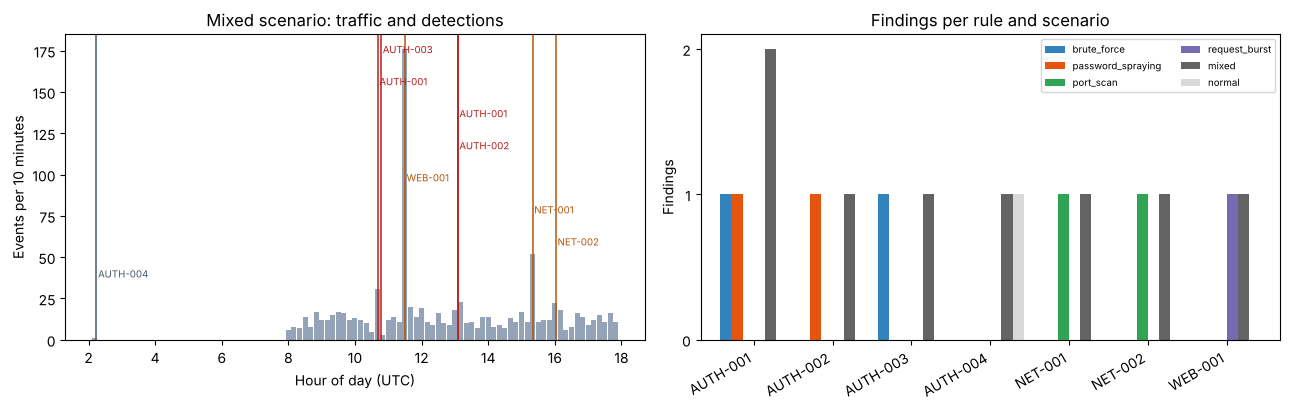

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Left: events per 10 minute bin for the mixed scenario, with each finding marked
evs = SCENARIOS["mixed"]["events"]
bins = Counter(int((e.t - DAY) // 600) for e in evs)
xs = sorted(bins)
axes[0].bar([x * 10 / 60 for x in xs], [bins[x] for x in xs], width=10 / 60 * 0.9, color="#94A3B8")
colors = {"critical": "#B91C1C", "high": "#B91C1C", "medium": "#B45309", "low": "#475569"}
top = axes[0].get_ylim()[1]
for j, f in enumerate(mixed):
    t = (datetime.fromisoformat(f.first_seen.replace("Z", "+00:00")).timestamp() - DAY) / 3600
    axes[0].axvline(t, color=colors[f.severity], lw=1.2, alpha=0.9)
    axes[0].text(t + 0.05, top * (0.97 - 0.105 * j), f.rule_id, va="top", ha="left", fontsize=7, color=colors[f.severity])
axes[0].set_xlabel("Hour of day (UTC)"); axes[0].set_ylabel("Events per 10 minutes")
axes[0].set_title("Mixed scenario: traffic and detections")

# Right: findings per rule per scenario
tab = pd.DataFrame({k: Counter(x.rule_id for x in v) for k, v in results.items()}).fillna(0).astype(int).reindex(list(RULES)).fillna(0)
tab.plot(kind="bar", ax=axes[1], width=0.85, colormap="tab20c")
axes[1].yaxis.get_major_locator().set_params(integer=True)
axes[1].set_title("Findings per rule and scenario"); axes[1].set_xlabel(""); axes[1].set_ylabel("Findings")
axes[1].legend(fontsize=7, ncol=2); plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.savefig(OUT / "ids_charts.png", dpi=140); plt.show()

### A7. Changing a threshold changes the result

Thresholds are editable inside the safe range. Values outside the range are rejected, so a typing mistake cannot disable a rule silently.

In [9]:
base = analyse(SCENARIOS["brute_force"]["events"])
strict = default_config(); strict["AUTH-001"]["threshold"] = 50; strict["AUTH-003"]["failures"] = 50
relaxed = analyse(SCENARIOS["brute_force"]["events"], strict)
print("Default thresholds   :", [f.rule_id for f in base])
print("Threshold set to 50  :", [f.rule_id for f in relaxed])
assert len(relaxed) < len(base)

bad = default_config(); bad["AUTH-001"]["threshold"] = 999
try:
    analyse(SCENARIOS["brute_force"]["events"], bad)
except ValueError as e:
    print("Rejected out-of-range value ->", e)
else:
    raise AssertionError("Out-of-range threshold was accepted")

Default thresholds   : ['AUTH-003', 'AUTH-001']
Threshold set to 50  : []
Rejected out-of-range value -> AUTH-001.threshold must be a whole number from 2 to 50, got 999


### A8. CSV import and validation

Uploaded logs are untrusted input. The validator checks the file before analysis and reports each bad row with its row number, so one malformed line does not hide the rest.

Limits: 5 MB and 50,000 rows. Required columns: `timestamp`, `event_type`, `src_ip`. A timestamp without a time zone is read as UTC.

In [10]:
MAX_BYTES, MAX_ROWS = 5 * 1024 * 1024, 50_000
REQUIRED = ("timestamp", "event_type", "src_ip")

def parse_ts(s):
    try:
        d = datetime.fromisoformat(s.strip().replace("Z", "+00:00"))
    except ValueError:
        return None
    return (d if d.tzinfo else d.replace(tzinfo=timezone.utc)).timestamp()

def is_ip(s):
    try: ipaddress.ip_address(s); return True
    except ValueError: return False

def validate_csv(text, file_name="upload.csv"):
    """Return (events, errors, fatal). fatal is a message when the whole file is rejected."""
    if not file_name.lower().endswith(".csv"): return [], [], "The file must have a .csv extension."
    if len(text.encode("utf-8")) > MAX_BYTES: return [], [], "The file is larger than 5 MB."
    if not text.strip(): return [], [], "The file is empty."
    rows = list(csv.reader(io.StringIO(text)))
    header = [h.strip().lower() for h in rows[0]]
    missing = [c for c in REQUIRED if c not in header]
    if missing: return [], [], "Missing required column(s): " + ", ".join(missing) + "."
    data = rows[1:]
    if not data: return [], [], "The file has a header but no data rows."
    if len(data) > MAX_ROWS: return [], [], f"The file has {len(data):,} rows. The limit is {MAX_ROWS:,}."
    col = lambda r, n: (r[header.index(n)].strip() if n in header and header.index(n) < len(r) else "")
    events, errors, seen = [], [], set()
    for n, r in enumerate(data, start=2):
        bad = lambda field, msg: errors.append({"row": n, "field": field, "problem": msg})
        before = len(errors)
        ts, typ, src, dst, port, user = (col(r, c) for c in ("timestamp", "event_type", "src_ip", "dst_ip", "dst_port", "username"))
        eid = col(r, "event_id") or f"row-{n - 1}"
        t = parse_ts(ts)
        if t is None: bad("timestamp", f"{ts[:30]!r} is not an ISO 8601 time")
        if typ not in EVENT_TYPES: bad("event_type", f"{typ[:30]!r} is not one of {', '.join(EVENT_TYPES)}")
        if not is_ip(src): bad("src_ip", f"{src[:40]!r} is not a valid IP address")
        if dst and not is_ip(dst): bad("dst_ip", f"{dst[:40]!r} is not a valid IP address")
        p = None
        if port:
            if port.isdigit() and 0 <= int(port) <= 65535: p = int(port)
            else: bad("dst_port", f"{port[:12]!r} is not a port from 0 to 65535")
        if len(user) > 128: bad("username", "longer than 128 characters")
        if typ == "conn" and (not dst or not port): bad("dst_ip", "conn events need dst_ip and dst_port")
        if typ in ("auth_failure", "auth_success") and not user: bad("username", "authentication events need a username")
        if eid in seen: bad("event_id", f"duplicate event_id {eid[:30]!r}")
        if len(errors) == before:
            seen.add(eid)
            events.append(Event(eid[:64], t, typ, src, dst or None, p, user or None, col(r, "service") or None, col(r, "status") or None))
    return events, errors, None

GOOD = "event_id,timestamp,event_type,src_ip,username,service\n" + "\n".join(
    f"g{i},2026-10-24T10:00:{i * 5:02d}Z,auth_failure,203.0.113.9,root,ssh" for i in range(8)) + "\n"
MALFORMED = """event_id,timestamp,event_type,src_ip,dst_ip,dst_port,username
m-1,2026-10-24T10:00:00Z,auth_failure,203.0.113.45,,,admin
m-2,not-a-date,auth_failure,203.0.113.45,,,admin
m-3,2026-10-24T10:00:40Z,login_attempt,203.0.113.45,,,admin
m-4,2026-10-24T10:00:50Z,conn,999.1.1.1,192.0.2.10,70000,
m-5,2026-10-24T10:01:00Z,auth_failure,203.0.113.45,,,
m-1,2026-10-24T10:01:10Z,auth_failure,203.0.113.45,,,admin
"""

ev, err, fatal = validate_csv(GOOD)
print("Valid file   :", len(ev), "events accepted,", len(err), "errors")
print("Analysis of the uploaded file ->", [f.rule_id for f in analyse(ev)])
assert len(ev) == 8 and not err and [f.rule_id for f in analyse(ev)] == ["AUTH-001"]

ev, err, fatal = validate_csv(MALFORMED, "malformed.csv")
print("\nMalformed file:", len(ev), "accepted,", len(err), "row errors")
display(pd.DataFrame(err))
assert len(ev) == 1 and len(err) == 6

for text, name in [("a,b\n1,2\n", "x.csv"), ("hello", "x.txt"), ("", "x.csv")]:
    print("Rejected:", validate_csv(text, name)[2])
assert validate_csv("timestamp,event_type,src_ip\n" + "x" * (5 * 1024 * 1024), "big.csv")[2] == "The file is larger than 5 MB."

Valid file   : 8 events accepted, 0 errors
Analysis of the uploaded file -> ['AUTH-001']

Malformed file: 1 accepted, 6 row errors


,row,field,problem
0,3,timestamp,'not-a-date' is not an ISO 8601 time
1,4,event_type,"'login_attempt' is not one of auth_success, auth_failure, conn, ht..."
2,5,src_ip,'999.1.1.1' is not a valid IP address
3,5,dst_port,'70000' is not a port from 0 to 65535
4,6,username,authentication events need a username
5,7,event_id,duplicate event_id 'm-1'


Rejected: Missing required column(s): timestamp, event_type, src_ip.
Rejected: The file must have a .csv extension.
Rejected: The file is empty.


### A9. Export findings (JSON, CSV, Markdown)

CSV cells that start with `=`, `+`, `-` or `@` are prefixed so a spreadsheet cannot run them as formulas.

In [11]:
def csv_cell(v):
    s = "" if v is None else str(v)
    return "'" + s if s[:1] in ("=", "+", "-", "@", "\t", "\r") else s

def export_json(findings, source, n_events, path):
    doc = {"tool": "Tellwarden Offline IDS Simulator", "notice": "Offline simulation of sample data. Not live monitoring.",
           "source": source, "events_analysed": n_events, "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
           "findings": [asdict(f) for f in findings]}
    Path(path).write_text(json.dumps(doc, indent=2), encoding="utf-8")

def export_csv(findings, path):
    cols = ["id", "rule_id", "rule_name", "severity", "entity", "first_seen", "last_seen", "observed", "threshold"]
    buf = io.StringIO(); w = csv.writer(buf)
    w.writerow(cols + ["evidence_events"])
    for f in findings: w.writerow([csv_cell(getattr(f, c)) for c in cols] + [len(f.evidence_ids)])
    Path(path).write_text(buf.getvalue(), encoding="utf-8")

def export_markdown(findings, source, n_events, path):
    esc = lambda s: re.sub(r"([|\\`*_{}\[\]<>#])", r"\\\1", str(s))
    lines = ["# Tellwarden IDS simulation report", "", "> Offline simulation of sample data. Not live monitoring.", "",
             f"- Source: {esc(source)}", f"- Events analysed: {n_events}", f"- Findings: {len(findings)}", "",
             "| Severity | Rule | Entity | First seen | Observed |", "|---|---|---|---|---|"]
    lines += [f"| {f.severity} | {f.rule_id} | {esc(f.entity)} | {f.first_seen} | {esc(f.observed)} |" for f in findings]
    for f in findings:
        lines += ["", f"## {f.rule_id} {esc(f.rule_name)} ({f.severity})", "", f"Entity: {esc(f.entity)}", "",
                  f"Why it matters: {esc(f.explanation)}", "", f"Suggested response: {esc(f.response)}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")

n = len(SCENARIOS["mixed"]["events"])
export_json(mixed, "scenario: mixed", n, OUT / "ids_findings.json")
export_csv(mixed, OUT / "ids_findings.csv")
export_markdown(mixed, "scenario: mixed", n, OUT / "ids_report.md")
assert json.loads((OUT / "ids_findings.json").read_text())["findings"], "JSON export is empty"
assert csv_cell("=cmd|' /C calc'!A0").startswith("'=")
print("Written:", sorted(p.name for p in OUT.iterdir()))

Written: ['ids_charts.png', 'ids_findings.csv', 'ids_findings.json', 'ids_report.md', 'scan_report_typical.json', 'scan_report_typical.md', 'scanner_chart.png']


## Part B. Web Security Scanner

### B1. Safe target handling

A scanner can be abused to reach internal systems (SSRF). Two guards protect against this.

1. **Text check** of the URL: scheme must be http or https, no embedded credentials, only ports 80 and 443, no `localhost` or internal names.
2. **Address check** after DNS resolution: every resolved address must be public. Loopback, private, link-local, multicast, reserved and cloud metadata addresses are refused.

This notebook uses the text check on its own for the offline analysis, and both checks before any live request.

In [12]:
BLOCKED_NAMES = {"localhost", "metadata.google.internal"}

def check_url(raw):
    """Return (ok, url_or_reason). Looks at the text only. Makes no network call."""
    text = raw.strip()
    if not text: return False, "Enter a website address, for example https://example.test."
    if len(text) > 2048: return False, "The address is longer than 2048 characters."
    try:
        u = urlsplit(text); port = u.port
    except ValueError:
        return False, "This is not a valid address."
    if u.scheme not in ("http", "https") or not u.hostname: return False, "Only http and https addresses are allowed."
    if u.username or u.password: return False, "Addresses with a username or password are not allowed."
    if port not in (None, 80, 443): return False, "Only ports 80 and 443 are allowed."
    host = u.hostname.lower()
    if host in BLOCKED_NAMES or host.endswith((".localhost", ".internal", ".local")):
        return False, "Local and internal host names are blocked."
    try:
        if not ipaddress.ip_address(host).is_global: return False, "Private, loopback and link-local addresses are blocked."
    except ValueError:
        pass
    return True, text

def address_is_public(ip_text):
    ip = ipaddress.ip_address(ip_text)
    return ip.is_global and not ip.is_multicast

tests = {"https://example.test": True, "http://localhost:8080": False, "ftp://example.test": False,
         "https://user:pw@example.test": False, "https://10.0.0.5": False, "https://169.254.169.254/latest": False,
         "https://example.test:8443": False, "not a url": False, "https://[::1]/": False, "http://192.168.1.1": False}
for raw, want in tests.items():
    ok, info = check_url(raw)
    print(f"{'allowed' if ok else 'blocked':8} {raw:38} {'' if ok else info}")
    assert ok == want, raw
assert address_is_public("93.184.216.34") and not address_is_public("127.0.0.1") and not address_is_public("169.254.169.254")

allowed  https://example.test                   
blocked  http://localhost:8080                  Only ports 80 and 443 are allowed.
blocked  ftp://example.test                     Only http and https addresses are allowed.
blocked  https://user:pw@example.test           Addresses with a username or password are not allowed.
blocked  https://10.0.0.5                       Private, loopback and link-local addresses are blocked.
blocked  https://169.254.169.254/latest         Private, loopback and link-local addresses are blocked.
blocked  https://example.test:8443              Only ports 80 and 443 are allowed.
blocked  not a url                              Only http and https addresses are allowed.
blocked  https://[::1]/                         Private, loopback and link-local addresses are blocked.
blocked  http://192.168.1.1                     Private, loopback and link-local addresses are blocked.


### B2. Security checks

Each check is a pure function that reads a **response snapshot** and returns a status:

* `pass`, the setting is good
* `warning`, present but weak, or a small gap
* `fail`, missing or clearly unsafe
* `info`, situational, no score impact

A snapshot is a dictionary with `final_url`, `redirect_chain`, `tls_ok`, `http_redirects_to_https`, `headers`, `set_cookie` and an optional `cors` probe. Using snapshots means the checks can be tested without touching any network.

In [13]:
def R(cid, group, name, status, observed, fix="No action needed."):
    return {"id": cid, "group": group, "check": name, "status": status, "observed": observed, "fix": fix}

def hget(s, name):
    return {k.lower(): v for k, v in s["headers"].items()}.get(name.lower())

def chk_https_final(s):
    ok = s["final_url"].lower().startswith("https://")
    return R("HTTPS-01", "HTTPS", "Final URL uses HTTPS", "pass" if ok else "fail",
             "The final address uses https." if ok else "The final address uses plain http.",
             "Serve the site over HTTPS and redirect all http traffic to it.")

def chk_tls(s):
    if s.get("tls_ok") is None: return R("HTTPS-02", "HTTPS", "Certificate verifies", "info", "Not tested for this snapshot.")
    return R("HTTPS-02", "HTTPS", "Certificate verifies", "pass" if s["tls_ok"] else "fail",
             "The certificate chain verified and matches the host name." if s["tls_ok"] else "Certificate verification failed.",
             "Install a valid certificate from a trusted authority that covers the host name.")

def chk_http_redirect(s):
    v = s.get("http_redirects_to_https")
    if v is None: return R("HTTPS-03", "HTTPS", "HTTP redirects to HTTPS", "info", "Not tested for this snapshot.")
    return R("HTTPS-03", "HTTPS", "HTTP redirects to HTTPS", "pass" if v else "fail",
             "Requests to http redirect to https." if v else "The http address answers without redirecting to https.",
             "Add a permanent redirect (301 or 308) from http to https on the same host.")

def chk_downgrade(s):
    chain = [u for u, _ in s["redirect_chain"]]
    down = any(a.startswith("https://") and b.startswith("http://") for a, b in zip(chain, chain[1:]))
    return R("HTTPS-04", "HTTPS", "No downgrade in redirect chain", "fail" if down else "pass",
             "The redirect chain contains a hop from https to http." if down else "No https to http hop in the redirect chain.",
             "Change the redirect target to an https address and re-test the full chain.")

def chk_hsts(s):
    v = hget(s, "strict-transport-security")
    fix = "Send Strict-Transport-Security with max-age of at least 31536000 and includeSubDomains."
    if not v: return R("HDR-01", "Security headers", "Strict-Transport-Security", "fail", "The header is missing.", fix)
    m = re.search(r"max-age=(\d+)", v, re.I); age = int(m.group(1)) if m else 0
    sub = "includesubdomains" in v.lower()
    if age >= 31536000 and sub: return R("HDR-01", "Security headers", "Strict-Transport-Security", "pass", f"max-age={age} with includeSubDomains.")
    gaps = ([f"max-age is {age} s"] if age < 31536000 else []) + ([] if sub else ["includeSubDomains is not set"])
    return R("HDR-01", "Security headers", "Strict-Transport-Security", "warning", "HSTS is present but " + " and ".join(gaps) + ".", fix)

def chk_csp(s):
    v = hget(s, "content-security-policy")
    fix = "Define a Content-Security-Policy without unsafe-inline or unsafe-eval. Start with default-src 'self'."
    if not v: return R("HDR-02", "Security headers", "Content-Security-Policy", "fail", "The header is missing.", fix)
    weak = [x for x in ("unsafe-inline", "unsafe-eval") if x in v] + (["a wildcard source"] if re.search(r"(^|\s)\*(\s|;|$)", v) else [])
    if weak: return R("HDR-02", "Security headers", "Content-Security-Policy", "warning", "The policy allows " + ", ".join(weak) + ".", fix)
    return R("HDR-02", "Security headers", "Content-Security-Policy", "pass", "A restrictive policy is present.")

def chk_nosniff(s):
    v = (hget(s, "x-content-type-options") or "").lower()
    return R("HDR-03", "Security headers", "X-Content-Type-Options", "pass" if v == "nosniff" else "fail",
             "The header is present with the value nosniff." if v == "nosniff" else "The header is missing or has the wrong value.",
             "Send X-Content-Type-Options: nosniff.")

def chk_framing(s):
    xfo = (hget(s, "x-frame-options") or "").upper(); csp = hget(s, "content-security-policy") or ""
    ok = xfo in ("DENY", "SAMEORIGIN") or "frame-ancestors" in csp
    return R("HDR-04", "Security headers", "Framing protection", "pass" if ok else "fail",
             "Framing is restricted." if ok else "Neither X-Frame-Options nor frame-ancestors is set.",
             "Send Content-Security-Policy: frame-ancestors 'self' (or X-Frame-Options: SAMEORIGIN).")

def chk_referrer(s):
    v = hget(s, "referrer-policy")
    ok = v and v.lower() in ("no-referrer", "same-origin", "strict-origin", "strict-origin-when-cross-origin", "origin-when-cross-origin")
    return R("HDR-05", "Security headers", "Referrer-Policy", "pass" if ok else "warning",
             f"Referrer-Policy is {v}." if ok else "The header is missing or unsafe, so the browser default applies.",
             "Send Referrer-Policy: strict-origin-when-cross-origin.")

def chk_permissions(s):
    return R("HDR-06", "Security headers", "Permissions-Policy", "pass" if hget(s, "permissions-policy") else "info",
             "The header is present." if hget(s, "permissions-policy") else "The header is missing. Informational, many sites do not need it.",
             "Send Permissions-Policy to turn off browser features the site does not use.")

def chk_coop(s):
    return R("HDR-07", "Security headers", "Cross-Origin-Opener-Policy", "pass" if hget(s, "cross-origin-opener-policy") else "info",
             "The header is present." if hget(s, "cross-origin-opener-policy") else "The header is missing. Situational, reported as information only.")

def chk_cache_cookie(s):
    if not s.get("set_cookie"): return R("HDR-09", "Security headers", "Cache-Control on cookie responses", "info", "No cookie was set in this response.")
    cc = (hget(s, "cache-control") or "").lower()
    ok = "no-store" in cc or "private" in cc
    return R("HDR-09", "Security headers", "Cache-Control on cookie responses", "pass" if ok else "warning",
             f"Cache-Control is {cc}." if ok else "A response that sets a cookie can be cached (no no-store or private).",
             "Send Cache-Control: no-store (or private) on responses that set cookies.")

def chk_server(s):
    leaks = [f"{h}: {hget(s, h)}" for h in ("server", "x-powered-by") if hget(s, h) and re.search(r"\d", hget(s, h))]
    return R("HDR-10", "Security headers", "Server and X-Powered-By", "warning" if leaks else "pass",
             "Version information is disclosed (" + "; ".join(leaks) + ")." if leaks else "No product version is disclosed.",
             "Remove version numbers from the Server and X-Powered-By headers.")

def chk_cors(s):
    c = s.get("cors")
    if c is None: return [R("CORS-01", "CORS", "Cross-origin access policy", "info", "No CORS probe in this snapshot.")]
    acao, creds, vary = c.get("acao"), str(c.get("acac", "")).lower() == "true", "origin" in (c.get("vary") or "").lower()
    probe = c["origin"]
    if acao is None: return [R("CORS-01", "CORS", "Cross-origin access policy", "pass", "The test origin is not allowed.")]
    if acao == "*" and creds: st, obs = "fail", "A wildcard origin is combined with credentials."
    elif acao == probe and creds: st, obs = "fail", "The test origin is reflected and credentials are allowed."
    elif acao == probe: st, obs = "warning", "The test origin is reflected. Credentials are not allowed."
    elif acao == "*": st, obs = "warning", "Any origin is allowed (wildcard)."
    else: st, obs = "pass", f"Only {acao} is allowed."
    out = [R("CORS-03", "CORS", "Cross-origin access policy", st, obs, "Replace reflection or wildcards with an allowlist of trusted origins.")]
    if acao == probe and not vary:
        out.append(R("CORS-07", "CORS", "Vary: Origin on CORS responses", "warning", "The origin is reflected but Vary: Origin is missing.", "Add Vary: Origin to responses whose CORS headers depend on the request origin."))
    return out

CHECKS = [chk_https_final, chk_tls, chk_http_redirect, chk_downgrade, chk_hsts, chk_csp, chk_nosniff, chk_framing,
          chk_referrer, chk_permissions, chk_coop, chk_cache_cookie, chk_server]

def scan_snapshot(s):
    res = [c(s) for c in CHECKS]
    cors = chk_cors(s); res += cors
    return pd.DataFrame(res)
print(len(CHECKS) + 1, "check functions ready.")

14 check functions ready.


### B3. Three sample responses

These snapshots are hand-written examples of a poorly configured, an average and a well configured site. Nothing here was measured from a real website.

In [14]:
SNAPSHOTS = {
  "weak": dict(final_url="http://shop.example.test/", redirect_chain=[("https://shop.example.test/", 302), ("http://shop.example.test/home", 200)],
               tls_ok=False, http_redirects_to_https=False, set_cookie=["sid=abc"],
               headers={"Server": "Apache/2.4.41 (Ubuntu)", "X-Powered-By": "PHP/7.4.3"},
               cors=dict(origin="https://origin.test", acao="https://origin.test", acac="true", vary=None)),
  "typical": dict(final_url="https://www.example.test/", redirect_chain=[("http://www.example.test/", 301)],
               tls_ok=True, http_redirects_to_https=True, set_cookie=["sid=abc"],
               headers={"Strict-Transport-Security": "max-age=86400", "X-Content-Type-Options": "nosniff",
                        "Content-Security-Policy": "frame-ancestors 'self'", "Cache-Control": "no-cache", "Server": "nginx/1.24.0"},
               cors=dict(origin="https://origin.test", acao="https://origin.test", acac="false", vary=None)),
  "strong": dict(final_url="https://secure.example.test/", redirect_chain=[("http://secure.example.test/", 301)],
               tls_ok=True, http_redirects_to_https=True, set_cookie=["sid=abc; Secure; HttpOnly"],
               headers={"Strict-Transport-Security": "max-age=63072000; includeSubDomains; preload", "X-Content-Type-Options": "nosniff",
                        "Content-Security-Policy": "default-src 'self'; frame-ancestors 'self'", "Referrer-Policy": "strict-origin-when-cross-origin",
                        "Permissions-Policy": "camera=()", "Cache-Control": "no-store", "Server": "web"},
               cors=dict(origin="https://origin.test", acao=None, acac=None, vary=None)),
}
reports = {k: scan_snapshot(v) for k, v in SNAPSHOTS.items()}
counts = pd.DataFrame({k: r["status"].value_counts() for k, r in reports.items()}).reindex(["pass", "warning", "fail", "info"]).fillna(0).astype(int)
display(counts)
print("Typical site, details:")
display(reports["typical"][["id", "check", "status", "observed"]])

,weak,typical,strong
status,,,
pass,0,7,13
warning,4,6,0
fail,9,0,0
info,2,2,1


Typical site, details:


,id,check,status,observed
0,HTTPS-01,Final URL uses HTTPS,pass,The final address uses https.
1,HTTPS-02,Certificate verifies,pass,The certificate chain verified and matches the host name.
2,HTTPS-03,HTTP redirects to HTTPS,pass,Requests to http redirect to https.
3,HTTPS-04,No downgrade in redirect chain,pass,No https to http hop in the redirect chain.
4,HDR-01,Strict-Transport-Security,warning,HSTS is present but max-age is 86400 s and includeSubDomains is no...
5,HDR-02,Content-Security-Policy,pass,A restrictive policy is present.
6,HDR-03,X-Content-Type-Options,pass,The header is present with the value nosniff.
7,HDR-04,Framing protection,pass,Framing is restricted.
8,HDR-05,Referrer-Policy,warning,"The header is missing or unsafe, so the browser default applies."
9,HDR-06,Permissions-Policy,info,"The header is missing. Informational, many sites do not need it."


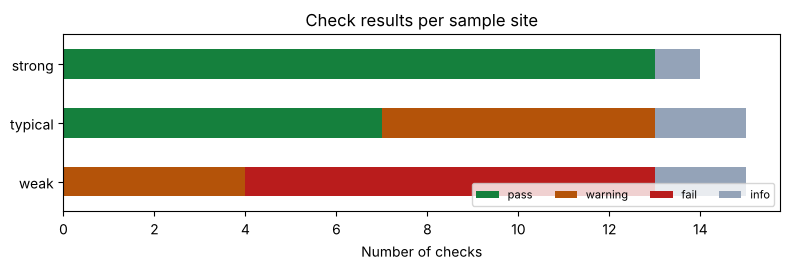

Scanner self-checks passed.


In [15]:
ax = counts.T.plot(kind="barh", stacked=True, figsize=(8, 2.8),
                   color={"pass": "#15803D", "warning": "#B45309", "fail": "#B91C1C", "info": "#94A3B8"})
ax.set_title("Check results per sample site"); ax.set_xlabel("Number of checks"); ax.legend(ncol=4, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "scanner_chart.png", dpi=140); plt.show()

# Self-checks
assert counts.loc["fail", "weak"] > counts.loc["fail", "typical"] > counts.loc["fail", "strong"] - 1
assert counts.loc["pass", "strong"] > counts.loc["pass", "weak"]
assert reports["strong"].loc[reports["strong"]["id"] == "HDR-02", "status"].item() == "pass"
assert reports["weak"].loc[reports["weak"]["id"] == "HDR-02", "status"].item() == "fail"
assert reports["weak"].loc[reports["weak"]["id"] == "CORS-03", "status"].item() == "fail"
assert reports["weak"].loc[reports["weak"]["id"] == "HTTPS-04", "status"].item() == "fail"
print("Scanner self-checks passed.")

### B4. Optional live fetch (off by default)

This function turns a real website response into a snapshot. It is **disabled** unless both flags below are set to `True`, because scanning a site you do not own or have permission to test can be illegal.

Safeguards in the function

* the URL passes `check_url` and every redirect target is checked again;
* the host name is resolved and **every** returned address must be public;
* redirects are followed by hand (maximum 5), body is never downloaded, timeout is 5 seconds;
* the User-Agent says it is an educational scanner.

A known limit: the address is checked and then the HTTP library resolves the name again. A hostile DNS server could answer differently the second time (DNS rebinding). The planned Streamlit application pins the connection to the checked address. This notebook is for learning, so run it only against your own sites.

In [16]:
LIVE_SCAN_ENABLED = False        # set both to True only for a site you own or have written permission to test
I_HAVE_PERMISSION = False

def resolve_public(host, allow_private=False):
    infos = socket.getaddrinfo(host, None, proto=socket.IPPROTO_TCP)
    addrs = {i[4][0] for i in infos}
    if not allow_private and not all(address_is_public(a) for a in addrs):
        raise PermissionError(f"{host} resolves to a non-public address: {sorted(addrs)}")
    return addrs

def fetch_snapshot(url, cors_origin="https://origin.test", allow_private=False):
    """allow_private exists only so the notebook can test this function against a local server."""
    import requests
    if not (LIVE_SCAN_ENABLED and I_HAVE_PERMISSION or allow_private):
        raise PermissionError("Live scanning is disabled. Set LIVE_SCAN_ENABLED and I_HAVE_PERMISSION to True for your own site.")
    ua = {"User-Agent": "Tellwarden/0.1 (educational scanner)"}
    def get(u, extra=None):
        if not allow_private:
            ok, info = check_url(u)
            if not ok: raise PermissionError(info)
        resolve_public(urlsplit(u).hostname, allow_private)
        return requests.get(u, headers={**ua, **(extra or {})}, allow_redirects=False, timeout=5, stream=True)
    tls_ok, chain, cur, resp = None, [], url, None
    for _ in range(6):
        try: resp = get(cur)
        except requests.exceptions.SSLError: tls_ok = False; raise
        chain.append((cur, resp.status_code))
        loc = resp.headers.get("Location")
        if resp.status_code in (301, 302, 303, 307, 308) and loc: resp.close(); cur = urljoin(cur, loc); continue
        break
    if cur.startswith("https://"): tls_ok = True
    h = dict(resp.headers)
    http_redirect = None
    host = urlsplit(url).hostname
    if cur.startswith("https://"):
        try:
            r2 = get(f"http://{host}/"); loc = r2.headers.get("Location", ""); r2.close()
            http_redirect = r2.status_code in (301, 302, 307, 308) and loc.startswith("https://")
        except Exception: http_redirect = None
    cors = None
    try:
        r3 = get(cur, {"Origin": cors_origin}); ch = r3.headers; r3.close()
        cors = dict(origin=cors_origin, acao=ch.get("Access-Control-Allow-Origin"), acac=ch.get("Access-Control-Allow-Credentials"), vary=ch.get("Vary"))
    except Exception: pass
    cookies = resp.raw.headers.get_all("Set-Cookie") if hasattr(resp.raw, "headers") and hasattr(resp.raw.headers, "get_all") else ([h["Set-Cookie"]] if "Set-Cookie" in h else [])
    resp.close()
    return dict(final_url=cur, redirect_chain=chain[:-1], tls_ok=tls_ok, http_redirects_to_https=http_redirect, headers=h, set_cookie=cookies or [], cors=cors)

# 1) The guard refuses by default.
try:
    fetch_snapshot("https://example.test")
except PermissionError as e:
    print("Default behaviour ->", e)

# 2) The address guard refuses a private target even when the flags are on.
LIVE_SCAN_ENABLED = I_HAVE_PERMISSION = True
try:
    fetch_snapshot("http://127.0.0.1/")
except PermissionError as e:
    print("Private target    ->", e)
LIVE_SCAN_ENABLED = I_HAVE_PERMISSION = False

Default behaviour -> Live scanning is disabled. Set LIVE_SCAN_ENABLED and I_HAVE_PERMISSION to True for your own site.
Private target    -> Private, loopback and link-local addresses are blocked.


In [17]:
# 3) Test the fetch code against a throwaway local server (test-only bypass of the address guard).
import threading
from http.server import BaseHTTPRequestHandler, HTTPServer

class Demo(BaseHTTPRequestHandler):
    def do_GET(self):
        self.send_response(200)
        for k, v in {"X-Content-Type-Options": "nosniff", "Set-Cookie": "sid=1",
                     "Access-Control-Allow-Origin": self.headers.get("Origin", "")}.items(): self.send_header(k, v)
        self.end_headers(); self.wfile.write(b"ok")
    def version_string(self): return "demo/1.0"
    def log_message(self, *a): pass

srv = HTTPServer(("127.0.0.1", 0), Demo); threading.Thread(target=srv.serve_forever, daemon=True).start()
try:
    snap = fetch_snapshot(f"http://127.0.0.1:{srv.server_port}/", allow_private=True)
finally:
    srv.shutdown()
live_df = scan_snapshot(snap)
display(live_df[["id", "check", "status", "observed"]])
assert snap["headers"]["Server"] == "demo/1.0" and snap["cors"]["acao"] == "https://origin.test"
assert live_df.loc[live_df["id"] == "HTTPS-01", "status"].item() == "fail"   # local test server is plain http
print("Local-server test passed. No external site was contacted.")

,id,check,status,observed
0,HTTPS-01,Final URL uses HTTPS,fail,The final address uses plain http.
1,HTTPS-02,Certificate verifies,info,Not tested for this snapshot.
2,HTTPS-03,HTTP redirects to HTTPS,info,Not tested for this snapshot.
3,HTTPS-04,No downgrade in redirect chain,pass,No https to http hop in the redirect chain.
4,HDR-01,Strict-Transport-Security,fail,The header is missing.
5,HDR-02,Content-Security-Policy,fail,The header is missing.
6,HDR-03,X-Content-Type-Options,pass,The header is present with the value nosniff.
7,HDR-04,Framing protection,fail,Neither X-Frame-Options nor frame-ancestors is set.
8,HDR-05,Referrer-Policy,warning,"The header is missing or unsafe, so the browser default applies."
9,HDR-06,Permissions-Policy,info,"The header is missing. Informational, many sites do not need it."


Local-server test passed. No external site was contacted.


### B5. Scanner report export

In [18]:
def scan_report_md(name, df, path):
    esc = lambda s: str(s).replace("|", "\\|")
    c = df["status"].value_counts().to_dict()
    lines = [f"# Tellwarden sample scan report: {name}", "",
             "> Demonstration on a hand-written sample response. Not a measurement of a real website.", "",
             f"Pass {c.get('pass', 0)}, Warning {c.get('warning', 0)}, Fail {c.get('fail', 0)}, Info {c.get('info', 0)}", "",
             "| ID | Check | Status | Observed |", "|---|---|---|---|"]
    lines += [f"| {r.id} | {esc(r.check)} | {r.status} | {esc(r.observed)} |" for r in df.itertuples()]
    lines += ["", "## Fixes", ""] + [f"* **{r.id} {r.check}**: {r.fix}" for r in df.itertuples() if r.status in ("fail", "warning")]
    lines += ["", "Results show selected configuration checks and are not a security guarantee."]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")

scan_report_md("typical", reports["typical"], OUT / "scan_report_typical.md")
reports["typical"].to_json(OUT / "scan_report_typical.json", orient="records", indent=2)
print(sorted(p.name for p in OUT.iterdir()))

['ids_charts.png', 'ids_findings.csv', 'ids_findings.json', 'ids_report.md', 'scan_report_typical.json', 'scan_report_typical.md', 'scanner_chart.png']


## Part C. Summary

**What was built**

* A deterministic rule engine with seven detections, bounded thresholds and evidence for every finding.
* A CSV validator that rejects bad rows with row numbers and limits file size.
* A scanner with thirteen check functions plus CORS probes, a two-stage SSRF guard and an optional, disabled-by-default live fetch.
* Exports in JSON, CSV and Markdown with spreadsheet-formula protection.
* Self-checks (`assert`) in every part. The notebook stops if a result is wrong.

**Limits**

* Rules use fixed thresholds in sliding windows. They can miss slow attacks and can flag busy normal periods.
* Data is synthetic. Real logs would need threshold tuning and false-positive review.
* The scanner reads response headers only. It does not test application logic, authentication or vulnerabilities in code.
* A passing scan does not mean a site is secure. A quiet log does not prove nothing happened.

**Responsible use.** Scan only systems you own or have written permission to test. The IDS here is an offline teaching tool, not a replacement for a production security monitoring system.

**Related files.** The same rules and sample data also power a browser prototype (React and TypeScript) that was built to demonstrate the user interface. It is described in the README and the project report.